In [1344]:
import numpy as np # Primary way to handle matrices and vectors, to model either a variable or a whole dataset
import pandas as pd # Has functions for analyzing, cleaning, exploring, and manipulating data
import matplotlib.pyplot as plt # Assists in the creation of informative visuals, which makes patterns and relationships within the data visible
import seaborn as sns # Popular data visualization library
import warnings # Allows to send warning messages to developers or users, and can be filtered in several ways; This is part of a 
# built-in class called Exception in Python


# One method of filtering, which just ignores the warnings if they match each filter requirement from the pre-established list of filtering parameters
warnings.filterwarnings('ignore')

# https://www.geeksforgeeks.org/warnings-in-python/

# makes sure that all the visualizations created are drawn within the notebook
%matplotlib inline

In [1345]:
# importing the dataset using a command from pandas; reads the file from the system/laptop

data_df = pd.read_csv("healthcare-dataset-stroke-data.csv")

In [1346]:
# shape of the dataset

print("The dataset has {} rows and {} columns".format(data_df.shape[0], data_df.shape[1]))

The dataset has 5110 rows and 12 columns


In [1347]:
# first and last few rows of the dataset; just need to run the variable in which the dataframe was stored

data_df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [1348]:
data_df.info() # The Info Function from Pandas; Object = categorical feature, while int64 && float64 = numerical

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [1349]:
data_df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [1350]:
# target variable stroke

data_df.stroke.value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [1351]:
data_df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [1352]:
# fill missing bmi values with mean, inplace=True because the operation has to be done to the original data frame

data_df["bmi"].fillna(data_df["bmi"].mean(), inplace=True)

In [1353]:
# print out the categorical data in the dataset, as they will need to be converted into numerical values for the neural network to process

data_df.select_dtypes(include=["object"]).head()

,gender,ever_married,work_type,Residence_type,smoking_status
0,Male,Yes,Private,Urban,formerly smoked
1,Female,Yes,Self-employed,Rural,never smoked
2,Male,Yes,Private,Rural,never smoked
3,Female,Yes,Private,Urban,smokes
4,Female,Yes,Self-employed,Rural,never smoked


**Label Encoding**

This is method when each label is converted into an integer value. It is a bad idea to perform label encoding on a dataset where an order is introduced to a feature where there is none. For example, the COUNTRY encoded as 3 is not 3 times bigger than what is encoded as 1. Therefore, label encoding is a good idean only when there is already a clear order within the feature or there are only 2 unique values, which would be converted to 1s and 0s.

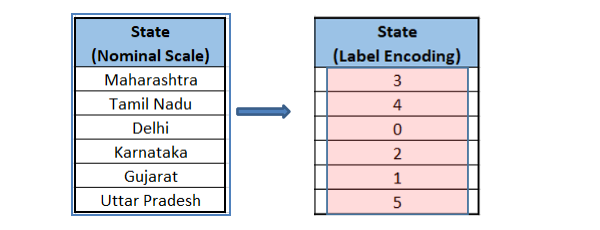 

- This would be a bad time to use this technique

In [1356]:
# LABEL ENCODING

# import label encoder from skikit-learn's preprocessing module
from sklearn.preprocessing import LabelEncoder

# create label encoder instance
le = LabelEncoder()

# fit label encoder to relevant features (the ones with only 2 possible values)

data_df["gender"] = le.fit_transform(data_df["gender"])

data_df["ever_married"] = le.fit_transform(data_df["ever_married"])

data_df["Residence_type"] = le.fit_transform(data_df["Residence_type"])

In [1357]:
data_df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,67.0,0,1,1,Private,1,228.69,36.600000,formerly smoked,1
1,51676,0,61.0,0,0,1,Self-employed,0,202.21,28.893237,never smoked,1
2,31112,1,80.0,0,1,1,Private,0,105.92,32.500000,never smoked,1
3,60182,0,49.0,0,0,1,Private,1,171.23,34.400000,smokes,1
4,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.000000,never smoked,1


**One-Hot Encoding**

This categorical data encoding technique is utilized when features are nominal and do not have a specified order. A new variable is created for each level of a categorical feature. Each category is mapped with a binary variable either containing 0 or 1. In this example, 0 represents the absence and 1 represents the precense of that category. These newly created binary features are known as **dummy features**. The number of dummy variables depends on the levels present in the original categorical variable.

(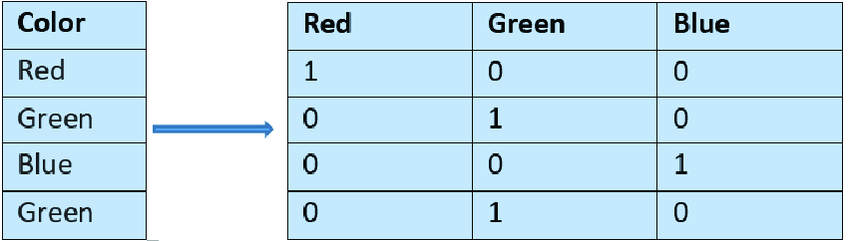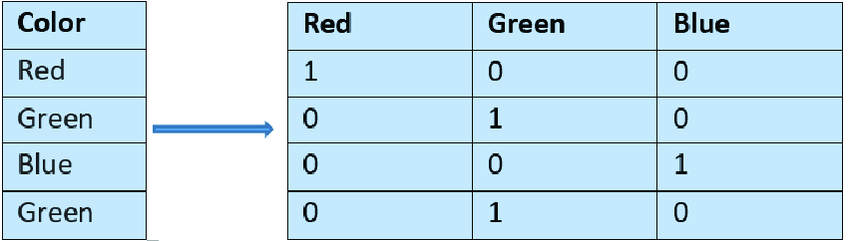)

In [1360]:
# one-hot encoding work type feature; prefix just sets something to appear before each of the dummy variables
work_type_ohe = pd.get_dummies(data_df.work_type, dtype='int', prefix="work")

work_type_ohe.head()

,work_Govt_job,work_Never_worked,work_Private,work_Self-employed,work_children
0,0,0,1,0,0
1,0,0,0,1,0
2,0,0,1,0,0
3,0,0,1,0,0
4,0,0,0,1,0


In [1361]:
# ohe smoking status feature

smoking_status_ohe = pd.get_dummies(data_df.smoking_status, dtype = 'int', prefix="smoking")

smoking_status_ohe.head()

,smoking_Unknown,smoking_formerly smoked,smoking_never smoked,smoking_smokes
0,0,1,0,0
1,0,0,1,0
2,0,0,1,0
3,0,0,0,1
4,0,0,1,0


In [1362]:
# concatenating with original database, [axis=1] means that it is done along the columns, while [axis=0] refers to the rows
data_df = pd.concat([data_df, work_type_ohe], axis=1)

data_df = pd.concat([data_df, smoking_status_ohe], axis=1)

#remove original, inplace=True so deletion is done on the original dataframe

data_df.drop(["work_type", "smoking_status"], axis=1, inplace=True)

data_df.head()

,id,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_Govt_job,work_Never_worked,work_Private,work_Self-employed,work_children,smoking_Unknown,smoking_formerly smoked,smoking_never smoked,smoking_smokes
0,9046,1,67.0,0,1,1,1,228.69,36.600000,1,0,0,1,0,0,0,1,0,0
1,51676,0,61.0,0,0,1,0,202.21,28.893237,1,0,0,0,1,0,0,0,1,0
2,31112,1,80.0,0,1,1,0,105.92,32.500000,1,0,0,1,0,0,0,0,1,0
3,60182,0,49.0,0,0,1,1,171.23,34.400000,1,0,0,1,0,0,0,0,0,1
4,1665,0,79.0,1,0,1,0,174.12,24.000000,1,0,0,0,1,0,0,0,1,0


**Feature Scaling**

Feature Scaling is a technique to standardize the independent features present in the data in a fixed range. It is performed during the data pre-processing to handle highly varying magnitudes or values or units. If feature scaling was not done, then the machine learning algorithm tends to weigh greater values higher and consider smaller values as the lower values, regardless of the unit of the values. For example, in this dataset, age is in one range, but glucose levels are in higher different range. Hyptertension is in another range to these two altogether. THis is essential to fix, as the neural network gives undue importance to bigger values. So, they will all need to be standardized into the same range.

In [1364]:
from sklearn.preprocessing import StandardScaler

# Instantiated
std = StandardScaler()
columns = ['avg_glucose_level','bmi','age']

# This function of the standard scaler class is used on the relevant columns
scaled = std.fit_transform(data_df[['avg_glucose_level','bmi','age']])

# A seperate data frame is being created for the standardized columns
scaled = pd.DataFrame(scaled, columns=columns)

# The original features from the main data are being dropped
data_df = data_df.drop(columns=columns, axis=1)

# Concatenating the newly created data frame to the original one
data_df = pd.concat([data_df, scaled], axis=1)
data_df.head()

,id,gender,hypertension,heart_disease,ever_married,Residence_type,stroke,work_Govt_job,work_Never_worked,work_Private,work_Self-employed,work_children,smoking_Unknown,smoking_formerly smoked,smoking_never smoked,smoking_smokes,avg_glucose_level,bmi,age
0,9046,1,0,1,1,1,1,0,0,1,0,0,0,1,0,0,2.706375,1.001234e+00,1.051434
1,51676,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,2.121559,4.615554e-16,0.786070
2,31112,1,0,1,1,0,1,0,0,1,0,0,0,0,1,0,-0.005028,4.685773e-01,1.626390
3,60182,0,0,0,1,1,1,0,0,1,0,0,0,0,0,1,1.437358,7.154182e-01,0.255342
4,1665,0,1,0,1,0,1,0,0,0,1,0,0,0,1,0,1.501184,-6.357112e-01,1.582163


**Dropping Unnecessary Features**

In [1366]:
# drop id column, as it is irrelevant

data_df = data_df.drop("id", axis=1)

data_df.head()

,gender,hypertension,heart_disease,ever_married,Residence_type,stroke,work_Govt_job,work_Never_worked,work_Private,work_Self-employed,work_children,smoking_Unknown,smoking_formerly smoked,smoking_never smoked,smoking_smokes,avg_glucose_level,bmi,age
0,1,0,1,1,1,1,0,0,1,0,0,0,1,0,0,2.706375,1.001234e+00,1.051434
1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,2.121559,4.615554e-16,0.786070
2,1,0,1,1,0,1,0,0,1,0,0,0,0,1,0,-0.005028,4.685773e-01,1.626390
3,0,0,0,1,1,1,0,0,1,0,0,0,0,0,1,1.437358,7.154182e-01,0.255342
4,0,1,0,1,0,1,0,0,0,1,0,0,0,1,0,1.501184,-6.357112e-01,1.582163


**Train-Test Split**

In [1368]:
# splitting the data to X(features used to predict the target variable) and y(target variable)

y = data_df["stroke"]

X = data_df.drop("stroke", axis=1)

In [1369]:
from sklearn.model_selection import train_test_split

# Test size is 30%, so the Train Set would therefore be 70%. This would end up splitting the dataset into four, X_train, y_train, X_test, y_test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

**Dealing with Data Imbalance**

The dataset is heavily imbalanced, as the dataset doesn't have as much information to learn about the minority class as it does to learn about the majority class. This would make it biased towards the majority.

**Oversampling** is when the number of observations from the minority class are incremented, balancing the dataset. **It is only done on the training dataset**, as the test dataset needs to be preserved as it is, since this is what the model will encounter in the outside world.

SMOTE - Synthetic Minority Oversampling Technique is an oversampling technique where the synthetic samples are generated for the minority class. This algorithm helps to overcome the overfitting problem posed by random oversampling.

SMOTE works by selecting examples that are close in the feature space, drawing a line between the examples in the feature space and drawing a new sample at a point along that line.

Specifically, a random example from the minority class is first chosen. Then k of the nearest neighbor for that example are found(typically k=5). A randomly selected neighbor is chosen and a synthetic example is created at a randomly selected point between the two examples in feature space.

In [1371]:
# Counts of 1s and 0s before oversampling

print('Before OverSampling, counts of label 1: {}'.format(sum(y_train==1)))
print('Before OverSampling, counts of label 0: {}'.format(sum(y_train==0)))

Before OverSampling, counts of label 1: 160
Before OverSampling, counts of label 0: 3417


In [1372]:
!pip install imbalanced-learn

In [1373]:
from imblearn.over_sampling import SMOTE

In [1374]:
# instantiating SMOTE
sm = SMOTE(random_state=2)

X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)

print('After OverSampling, the shape of X_train: {}'.format(X_train_sm.shape))
print('After OverSampling, the shape of y_train: {}'.format(y_train_sm.shape))

print('After OverSampling, counts of label 1: {}'.format(sum(y_train_sm == 1 )))
print('After OverSampling, counts of label 0: {}'.format(sum(y_train_sm == 0)))

After OverSampling, the shape of X_train: (6834, 17)
After OverSampling, the shape of y_train: (6834,)
After OverSampling, counts of label 1: 3417
After OverSampling, counts of label 0: 3417


In [1379]:
!pip install tensorflow
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Dense

In [1381]:
# Need to first define the model's skeletal system. This command specifies to Keras that we are creating a model sequentially, and the output of 
# each layer we add is the input to the next layer that we specify.
model = Sequential()

"model.add" is used to add a layer to our neural network. We need to specify as an argument what type of layer we want. The argument Dense is used to specify a fully connected layer. Fully connected layers in a neural network are those layers where all the inputs from one layer are connected to every activation unit of the next layer.

The first parameter of the Dense layer is the number of neurons in the hidden layer, which is specified as 12. It could be 24, 32, 128, or any such
number, depending on the complexity of the problem. The # of hidden layers & and the # of neurons in each layer is something that has to be found
through trial and error. The next argument is the input_dimension, which is the number of features in the dataset. Lastly, the activation function has
to be specified, which is **relu** in this case.

In [1388]:
# define first hidden and visible layer.
model.add(Dense(12, input_dim = X_train_sm.shape[1], activation = "relu"))

In [1392]:
# define second hidden layer. 
# 8----> # of Neurons, Activation Function -----> Relu
# The input dimension doesn't need to specified, as we have defined the model to be sequential so Keras will automatically consider input_dim to be the
# same as the output of the last layer.
model.add(Dense(8, activation = "relu"))

In [1394]:
# define output layer. 
# A single node or neuron is used at the output layer, since there are only two categories.
# The sigmoid activation function is used at the output layer, as this will give the probability of a patient having stroke
# With this, we have finished the architecture of the network
model.add(Dense(1, activation = "sigmoid"))

In [1396]:
# Now, the network needs to be compiled
# define loss and optimizer
# Specifying the configurations of the training process
# The objective of the model is to minimize the loss function
# Loss is set to binary_crossentropy as this is a two-class classification problem
# There are many types of optimizers
# Utilizing adam optimizer as it is built on top of gradient descent
model.compile(loss = "binary_crossentropy", optimizer = "adam")

In [1398]:
# fit model to training data
# the model.fit function takes an oversampled X_train and y_train, and also the # of epochs
# One epoch is when the entire dataset is passed forward and backward through the neural network once. 
# The weights and biases are constantly adjusted with each epoch
# The epoch # is also something that needs to be played around with in order to find the right value
model.fit (X_train_sm, y_train_sm, epochs = 25)

Epoch 1/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.6100
Epoch 2/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4177
Epoch 3/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3846
Epoch 4/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3422
Epoch 5/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3384
Epoch 6/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3145
Epoch 7/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3058
Epoch 8/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3064
Epoch 9/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3003
Epoch 10/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2922
Epoch 11/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2774
Epoch 12/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2631
Epoch 13/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2661
Epoch 14/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2687
Epoch 15/25
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - lo

When the previous cell was ran, the model started training. The loss is steadily decreasing with each epoch. However, even if you see the loss keep decreasing when you increase the number of epochs, it must be done carefully, as this would cause overfitting. **Overfitting** is when the model learns the training data too well that it fails to do well on unseen test data.

In [1405]:
# After the model is trained, predictions need to be generated on the test set, which is done here.
# predictions
y_pred = model.predict(X_test)

48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [1413]:
y_pred # As expected, this shows the probability of the patient having a stroke. A threshold needs to be set after which we say the patient will suffer 
# a stroke. In the next cell, it is set as 0.5. Anything above that means the patient will have a stroke, anything below means that they're safe.

[0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,


In [1417]:
y_pred = [1 if i > 0.5 else 0 for i in y_pred]

In [1419]:
y_pred

[0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,


In [1423]:
# importing a couple of evalution metrics

from sklearn.metrics import fbeta_score, confusion_matrix

# Since this is an imbalanced dataset, accuracy is a bad evaluation metric

In [1431]:
# F1 score takes into account both precision and recall and gives equal importance to both of them, could possibly be something we could look into.
# Because this is a medical problem, we should give more importance to recall, as it would be a problem if we let a person who's going to suffer a heart
# attack go back thinking he or she won't. Even if we get some false positives, we definitely want to minimize the false negatives.
# Recall is the measure of the model correctly identifying true postives. Thus, for all the patients who actually have a stroke, recall tells us how
# many we have correctly identified as having a stroke. So, the fbeta score. F1 score itself is a specific variety of fbeta score, where the beta
# parameter is one, which means precision and recall get equal importance.
# Increasing the beta value gives recall more importance, while decreasing it gives precision more importance
# Fbeta takes in 3 arguments: The ground truth, the predicted value and the beta value
# Running this will give us a score, which will have more significance when it is compared with the scores of other DL or ML models
print("The Fbeta Score is -",fbeta_score(y_test, y_pred, beta = 2.0))

The Fbeta Score is - 0.3435114503816794


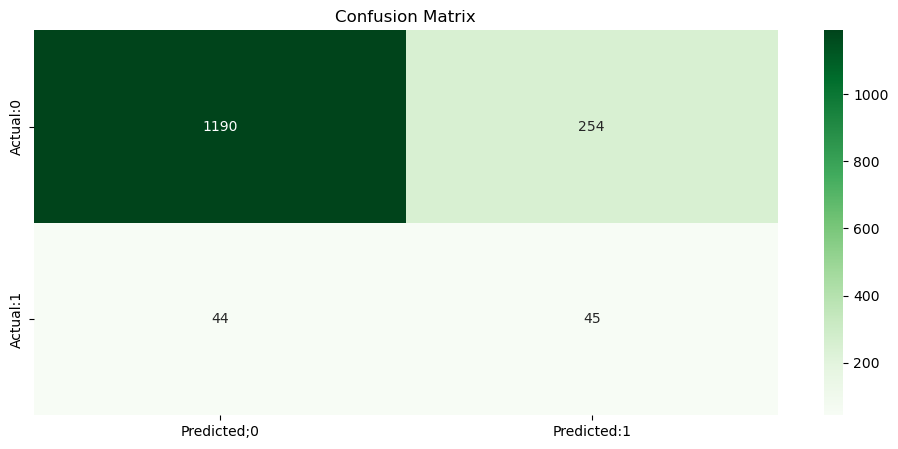

In [1435]:
# Using Seaborn to plot out the confusion matrix, which will give a more granular picture of how the model performed.

plt.figure(figsize=(12,5))

cm = confusion_matrix(y_test,y_pred)

conf_matrix = pd.DataFrame(data=cm,columns=['Predicted;0','Predicted:1'],index=['Actual:0','Actual:1'])

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap="Greens")

plt.title("Confusion Matrix")
plt.show()

# READING THE CONFUSION MATRIX
# When both the actual and predicted value of stroke was 0, the model got 1240 correct

# Struggled when the predicted value was 1 and the actual value was 0

# Most important thing to consider is what is shown on the bottom lefthand corner. When model predicted 0, 53 people actually had stroke. That needs to
# be minimized

# Some possible ways to minimize include hyperparameter tuning, future engineering etc, in order to decrease that score or increase the fbeta score